# Projeto Prático: Classificação de Óleo com Perceptron

Este projeto consiste na aplicação da rede neural `Perceptron` para resolver um problema real de classificação no setor de engenharia de petróleo.

### Descrição do Problema

Pela análise de um processo de destilação fracionada de petróleo, observou-se que determinado óleo poderia ser classificado em duas classes de pureza {P1 e P2} a partir da medição de três grandezas {x1, x2 e x3}, que representam algumas de suas propriedades físico-químicas.

Baseado nas informações coletadas do processo, formou-se o conjunto de treinamento apresentado no **Apêndice I** (disponível em `tabela_apendice_i.csv`), tomando por convenção:
- **Classe P1:** Valor -1
- **Classe P2:** Valor 1

O neurônio Perceptron terá então três entradas (x1, x2, x3) e uma saída (y). Utilizaremos o algoritmo supervisionado de Hebb (regra de Hebb) para o treinamento.

### Objetivos da Atividade

1.  **Executar cinco treinamentos** para a rede Perceptron, iniciando o vetor de pesos $\mathbf{w}$ em cada treinamento com valores aleatórios entre 0 e 1.
2.  **Garantir que os pesos iniciais sejam diferentes** em cada execução.
3.  **Registrar os resultados** (pesos iniciais, pesos finais e número de épocas).
4.  **Validar o modelo** utilizando um conjunto de amostras desconhecidas.

## Passo 1: Configuração e Carga de Dados

Primeiro, vamos importar as bibliotecas necessárias e carregar os dados de treinamento.

In [43]:
import numpy as np
import pandas as pd

# Configuração do gerador de números aleatórios para reprodutibilidade
rng = np.random.default_rng(42)

# Carregando os dados de treinamento
train_data = pd.read_csv('../arquivos-csv/tabela_apendice_i.csv')
print("Primeiras linhas do conjunto de treinamento:")
display(train_data.head())

Primeiras linhas do conjunto de treinamento:


,x1,x2,x3,d
0,-0.6508,0.1097,4.0009,-1.0
1,-1.4492,0.8896,4.4005,-1.0
2,2.0850,0.6876,12.0710,-1.0
3,0.2626,1.1476,7.7985,1.0
4,0.6418,1.0234,7.0427,1.0


## Passo 2: Definição da Classe Perceptron

Abaixo, unificamos a lógica do Perceptron em uma classe robusta que implementa a regra de Hebb.

In [44]:
class Perceptron:
    def __init__(self, weights, activation_func):
        # O vetor de pesos inclui o bias (w0) na primeira posição
        self.weights = weights
        self.activation_func = activation_func
        self.epochs = 0
        self.errors_history = []

    def feedforward(self, inputs):
        # Calcula o potencial de ativação u
        return np.dot(self.weights, inputs)

    def predict(self, inputs):
        # Aplica a função de ativação sobre o potencial u
        u = self.feedforward(inputs)
        return self.activation_func(u)

    def train(self, data, learning_rate=0.01, max_epochs=1000):
        for epoch in range(max_epochs):
            error_count = 0
            error_found_in_epoch = False

            for _, row in data.iterrows():
                # Entradas: x0=-1 (bias), x1, x2, x3
                x = np.array([-1, row['x1'], row['x2'], row['x3']])
                d = row['d']
                
                # Previsão atual
                y = self.predict(x)

                # Regra de Hebb: w = w + n*(d - y)*x
                if y != d:
                    self.weights = self.weights + learning_rate * (d - y) * x
                    error_found_in_epoch = True
                    error_count += 1

            self.errors_history.append(error_count)

            if not error_found_in_epoch:
                self.epochs = epoch + 1
                break
        return self.epochs

def bipolar_step(u):
    return 1 if u >= 0 else -1

## Passo 3: Execução dos Treinamentos

Conforme solicitado, executaremos o treinamento 5 vezes com diferentes pesos iniciais aleatórios entre 0 e 1.

In [45]:
results = []
trained_neurons = []

for i in range(5):
    # Pesos iniciais aleatórios [w0, w1, w2, w3]
    initial_weights = rng.random(4)
    
    # Criação e treinamento do neurônio
    neuron = Perceptron(initial_weights.copy(), bipolar_step)
    epochs = neuron.train(train_data)
    
    trained_neurons.append(neuron)
    
    # Salvando resultados para a tabela
    results.append({
        'Treinamento': i + 1,
        'w0_ini': initial_weights[0], 'w1_ini': initial_weights[1], 
        'w2_ini': initial_weights[2], 'w3_ini': initial_weights[3],
        'w0_fim': neuron.weights[0], 'w1_fim': neuron.weights[1], 
        'w2_fim': neuron.weights[2], 'w3_fim': neuron.weights[3],
        'Epocas': epochs
    })

df_results = pd.DataFrame(results)
print("Resultados processados:")
display(df_results)

Resultados processados:


,Treinamento,w0_ini,w1_ini,w2_ini,w3_ini,w0_fim,w1_fim,w2_fim,w3_fim,Epocas
0,1,0.773956,0.438878,0.858598,0.697368,-3.066044,1.552410,2.459394,-0.730494,425
1,2,0.094177,0.975622,0.761140,0.786064,-3.145823,1.592032,2.539484,-0.748530,437
2,3,0.128114,0.450386,0.370798,0.926765,-3.151886,1.594076,2.533020,-0.749279,439
3,4,0.643865,0.822762,0.443414,0.227239,-3.076135,1.533266,2.467998,-0.731211,395
4,5,0.554585,0.063817,0.827631,0.631664,-3.065415,1.553757,2.459203,-0.730374,418


### Gráfico dos Hiperplanos Iniciais

Abaixo visualizamos os 5 hiperplanos iniciais gerados pelos pesos aleatórios de cada treinamento. Como esperado de uma inicialização aleatória, os planos cortam o espaço de forma caótica, não separando as classes (indicando que a rede ainda não 'aprendeu').

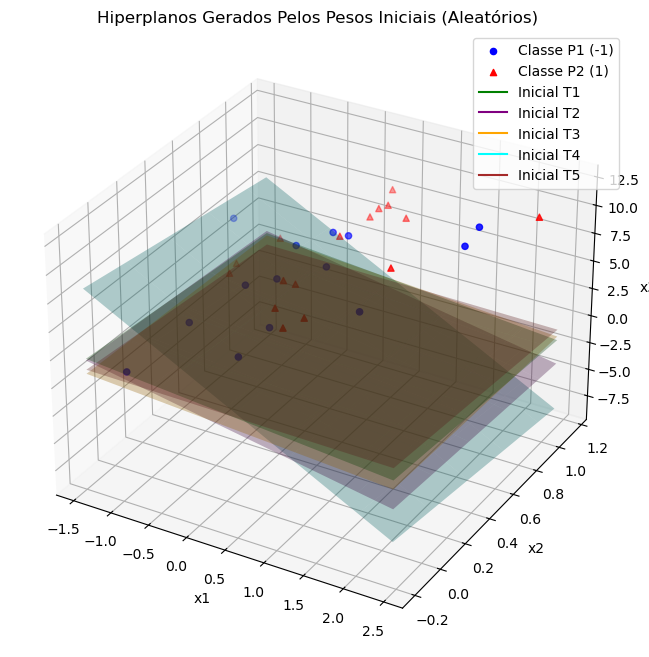

In [52]:
import matplotlib.pyplot as plt
import numpy as np

fig_ini = plt.figure(figsize=(12, 8))
ax_ini = fig_ini.add_subplot(111, projection='3d')

# Separando as classes para o plot
class_neg = train_data[train_data['d'] == -1]
class_pos = train_data[train_data['d'] == 1]

ax_ini.scatter(class_neg['x1'], class_neg['x2'], class_neg['x3'], c='blue', marker='o', label='Classe P1 (-1)')
ax_ini.scatter(class_pos['x1'], class_pos['x2'], class_pos['x3'], c='red', marker='^', label='Classe P2 (1)')

# Criando uma malha para x1 e x2
x1_range = np.linspace(train_data['x1'].min(), train_data['x1'].max(), 10)
x2_range = np.linspace(train_data['x2'].min(), train_data['x2'].max(), 10)
X1_ini, X2_ini = np.meshgrid(x1_range, x2_range)

colors = ['green', 'purple', 'orange', 'cyan', 'brown']

for i, row in df_results.iterrows():
    w0_ini = row['w0_ini']
    w1_ini = row['w1_ini']
    w2_ini = row['w2_ini']
    w3_ini = row['w3_ini']
    
    # A equação do hiperplano inicial é: u = -w0 + w1*x1 + w2*x2 + w3*x3 = 0
    # Isolando x3: x3 = (w0 - w1*x1 - w2*x2) / w3
    X3_ini = (w0_ini - w1_ini*X1_ini - w2_ini*X2_ini) / w3_ini
    
    # Plotando a malha (wireframe)
    ax_ini.plot_surface(X1_ini, X2_ini, X3_ini, color=colors[i], alpha=0.3, rstride=2, cstride=2)
    
    # Adicionando um objeto vazio para forçar a legenda da superfície
    ax_ini.plot([], [], [], color=colors[i], label=f'Inicial T{int(row["Treinamento"])}')

ax_ini.set_xlabel('x1')
ax_ini.set_ylabel('x2')
ax_ini.set_zlabel('x3')
ax_ini.set_title('Hiperplanos Gerados Pelos Pesos Iniciais (Aleatórios)')
ax_ini.legend()

# Ajustando o ângulo de visão
#ax_ini.view_init(elev=10, azim=25)

plt.show()

### Gráfico de Erros de Classificação

Abaixo, plotamos o comportamento do erro (número de classificações incorretas) ao longo das épocas para cada um dos 5 treinamentos realizados.

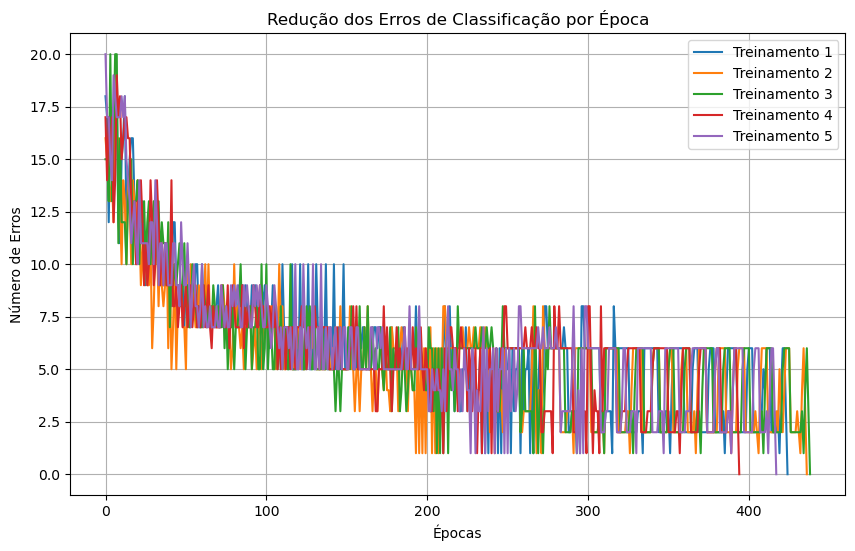

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for i, neuron in enumerate(trained_neurons):
    plt.plot(neuron.errors_history, label=f'Treinamento {i+1}')

plt.title('Redução dos Erros de Classificação por Época')
plt.xlabel('Épocas')
plt.ylabel('Número de Erros')
plt.legend()
plt.grid(True)
plt.show()

### Resultado dos treinamentos do Perceptron
| Treinamento | $w_{0}$ (inicial) | $w_{1}$ (inicial) | $w_{2}$ (inicial) | $w_{3}$ (inicial) | $w_{0}$ (final) | $w_{1}$ (final) | $w_{2}$ (final) | $w_{3}$ (final) | Épocas |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | 0.7739 | 0.4388 | 0.8585 | 0.6973 | -3.0660 | 1.5524 | 2.4593 | -0.7304 | 425 |
| 2 | 0.0941 | 0.9756 | 0.7611 | 0.7860 | -3.1458 | 1.5920 | 2.5394 | -0.7485 | 437 |
| 3 | 0.1281 | 0.4503 | 0.3707 | 0.9267 | -3.1518 | 1.5940 | 2.5330 | -0.7492 | 439 |
| 4 | 0.6438 | 0.8227 | 0.4434 | 0.2272 | -3.0761 | 1.5332 | 2.4679 | -0.7312 | 395 |
| 5 | 0.5545 | 0.0638 | 0.8276 | 0.6316 | -3.0654 | 1.5537 | 2.4592 | -0.7303 | 418 |

## Passo 4: Validação com Amostras Reais

Agora utilizaremos os 5 modelos treinados para classificar 10 novas amostras de óleo contidas no arquivo `amostras_oleo.csv`.

In [50]:
validation_data = pd.read_csv('../arquivos-csv/amostras_oleo.csv')

# Realizando as previsões para cada treinamento (T1 a T5)
for i, neuron in enumerate(trained_neurons):
    col_name = f'y_T{i+1}'
    predictions = []
    for _, row in validation_data.iterrows():
        x = np.array([-1, row['x1'], row['x2'], row['x3']])
        predictions.append(neuron.predict(x))
    validation_data[col_name] = predictions

print("Resultados da Validação:")
display(validation_data.head(10))

Resultados da Validação:


,Amostra,x1,x2,x3,y_T1,y_T2,y_T3,y_T4,y_T5
0,1,-0.3665,0.0620,5.9891,-1,-1,-1,-1,-1
1,2,-0.7842,1.1267,5.5912,1,1,1,1,1
2,3,0.3012,0.5611,5.8234,1,1,1,1,1
3,4,0.7757,1.0648,8.0677,1,1,1,1,1
4,5,0.1570,0.8028,6.3040,1,1,1,1,1
5,6,-0.7014,1.0316,3.6005,1,1,1,1,1
6,7,0.3748,0.1536,6.1537,-1,-1,-1,-1,-1
7,8,-0.6920,0.9404,4.4058,1,1,1,1,1
8,9,-1.3970,0.7141,4.9263,-1,-1,-1,-1,-1
9,10,-1.8842,-0.2805,1.2548,-1,-1,-1,-1,-1


### Amostras de óleo para validar o Perceptron
| Amostra | x1 | x2 | x3 | y_T1 | y_T2 | y_T3 | y_T4 | y_T5 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | -0.3665 | 0.0620 | 5.9891 | -1.0 | -1.0 | -1.0 | -1.0 | -1.0 |
| 2 | -0.7842 | 1.1267 | 5.5912 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 3 | 0.3012 | 0.5611 | 5.8234 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 4 | 0.7757 | 1.0648 | 8.0677 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 5 | 0.1570 | 0.8028 | 6.3040 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 6 | -0.7014 | 1.0316 | 3.6005 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 7 | 0.3748 | 0.1536 | 6.1537 | -1.0 | -1.0 | -1.0 | -1.0 | -1.0 |
| 8 | -0.6920 | 0.9404 | 4.4058 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| 9 | -1.3970 | 0.7141 | 4.9263 | -1.0 | -1.0 | -1.0 | -1.0 | -1.0 |
| 10 | -1.8842 | -0.2805 | 1.2548 | -1.0 | -1.0 | -1.0 | -1.0 | -1.0 |

## Visualização das Fronteiras de Decisão (Hiperplanos)

Para entender melhor como os 5 modelos separaram as classes no espaço tridimensional, vamos plotar os dados originais e as 5 superfícies (hiperplanos) resultantes.

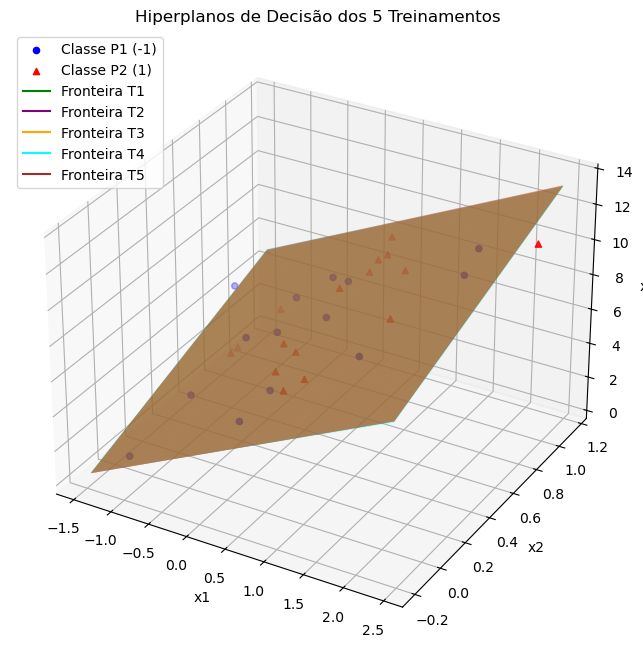

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Separando as classes para o plot
class_neg = train_data[train_data['d'] == -1]
class_pos = train_data[train_data['d'] == 1]

ax.scatter(class_neg['x1'], class_neg['x2'], class_neg['x3'], c='blue', marker='o', label='Classe P1 (-1)')
ax.scatter(class_pos['x1'], class_pos['x2'], class_pos['x3'], c='red', marker='^', label='Classe P2 (1)')

# Criando uma malha para x1 e x2
x1_range = np.linspace(train_data['x1'].min(), train_data['x1'].max(), 10)
x2_range = np.linspace(train_data['x2'].min(), train_data['x2'].max(), 10)
X1, X2 = np.meshgrid(x1_range, x2_range)

colors = ['green', 'purple', 'orange', 'cyan', 'brown']

for i, neuron in enumerate(trained_neurons):
    w0, w1, w2, w3 = neuron.weights
    
    # A equação do hiperplano é: u = -w0 + w1*x1 + w2*x2 + w3*x3 = 0
    # Isolando x3: x3 = (w0 - w1*x1 - w2*x2) / w3
    X3 = (w0 - w1*X1 - w2*X2) / w3
    
    # Plotando a malha (wireframe)
    ax.plot_surface(X1, X2, X3, color=colors[i], alpha=0.3, rstride=2, cstride=2)
    
    # Adicionando um objeto vazio para forçar a legenda da superfície
    ax.plot([], [], [], color=colors[i], label=f'Fronteira T{i+1}')

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Hiperplanos de Decisão dos 5 Treinamentos')
ax.legend()

plt.show()

## Conclusão

### Por que os hiperplanos (retas) parecem um só no gráfico?
Apesar de termos 5 inicializações diferentes de pesos, o algoritmo Perceptron (Regra de Hebb) encontrou um ponto de convergência **extremamente semelhante** para todos eles. Como o problema de separação das amostras possui um espaço muito claro de divisão, os pesos ajustados finais das 5 redes formaram equações quase idênticas. Assim, ao plotá-los, os hiperplanos se sobrepõem quase perfeitamente, provando que o modelo encontrou o "caminho ideal" independentemente de onde começou.

### O modelo é confiável?
Como podemos observar na tabela de validação, embora os pesos finais de cada treinamento sejam ligeiramente diferentes, as classificações tendem a ser consistentes entre os modelos. Isso ocorre porque existem infinitos hiperplanos que podem separar as duas classes no espaço tridimensional.

### Por que os pesos iniciais mudam o número de épocas?
A posição inicial da fronteira de decisão (reta/plano) no espaço depende dos pesos iniciais. Se a posição inicial estiver mais próxima da solução ideal, o algoritmo convergirá mais rápido (menos épocas).